# Лабораторная работа №4

## Бинарная классификация

Задание:
1. Импортировать датасет для бинарной классификации, т.е. целевой признак **должен быть бинарным**. Исходные данные можно выбрать:
- самостоятелно на kaggle.com;
- взять один из файлов, прикрепленных к заданию
- взять учебный набор данных из sklearn (например, `load_diabets`). 
2. Очистить датасет от пропусков и выбросов, если они есть, выполнить нормализацию, либо стандартизацию данных, если необходимо.
3. Выбрать целевую переменную и сформировать набор признаков.
4. Создать модель бинарной классификации на основе моделей логистической регрессии, SVM, CART.
5. Оценить качество моделей.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("data.csv")

df.head()

,Age,Height_cm,Weight_kg,Position,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,Injury_Next_Season,BMI
0,22,173,64,Midfielder,11.575308,36,1,77.460279,79.115738,284.487853,91.212476,5.874630,77.599705,8.238293,46.616415,81.472206,1,0,21.383942
1,18,170,67,Midfielder,12.275869,37,2,72.634442,82.541688,250.579249,87.294078,5.796269,94.418987,8.983737,49.368037,81.056677,1,0,23.183391
2,22,186,75,Forward,12.254896,12,2,77.064490,75.943631,269.119918,83.440688,5.731209,70.179176,7.229193,43.132808,64.877457,0,1,21.678807
3,20,172,62,Defender,9.006678,11,1,82.810232,73.878324,226.376412,87.591894,6.220212,83.473824,7.681029,51.528529,89.824744,1,0,20.957274
4,18,172,94,Midfielder,12.683668,10,2,76.772859,76.653043,229.021042,83.125161,5.385958,87.037256,6.728091,52.379718,71.569197,0,1,31.773932


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         800 non-null    int64  
 1   Height_cm                   800 non-null    int64  
 2   Weight_kg                   800 non-null    int64  
 3   Position                    800 non-null    object 
 4   Training_Hours_Per_Week     800 non-null    float64
 5   Matches_Played_Past_Season  800 non-null    int64  
 6   Previous_Injury_Count       800 non-null    int64  
 7   Knee_Strength_Score         800 non-null    float64
 8   Hamstring_Flexibility       800 non-null    float64
 9   Reaction_Time_ms            800 non-null    float64
 10  Balance_Test_Score          800 non-null    float64
 11  Sprint_Speed_10m_s          800 non-null    float64
 12  Agility_Score               800 non-null    float64
 13  Sleep_Hours_Per_Night       800 non

In [4]:
df.Position.unique()

array(['Midfielder', 'Forward', 'Defender', 'Goalkeeper'], dtype=object)

In [5]:
df = pd.get_dummies(df, columns=["Position"], prefix=["Is"], drop_first=True, dtype=int)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         800 non-null    int64  
 1   Height_cm                   800 non-null    int64  
 2   Weight_kg                   800 non-null    int64  
 3   Training_Hours_Per_Week     800 non-null    float64
 4   Matches_Played_Past_Season  800 non-null    int64  
 5   Previous_Injury_Count       800 non-null    int64  
 6   Knee_Strength_Score         800 non-null    float64
 7   Hamstring_Flexibility       800 non-null    float64
 8   Reaction_Time_ms            800 non-null    float64
 9   Balance_Test_Score          800 non-null    float64
 10  Sprint_Speed_10m_s          800 non-null    float64
 11  Agility_Score               800 non-null    float64
 12  Sleep_Hours_Per_Night       800 non-null    float64
 13  Stress_Level_Score          800 non

In [7]:
df.head(5)

,Age,Height_cm,Weight_kg,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,...,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,Injury_Next_Season,BMI,Is_Forward,Is_Goalkeeper,Is_Midfielder
0,22,173,64,11.575308,36,1,77.460279,79.115738,284.487853,91.212476,...,77.599705,8.238293,46.616415,81.472206,1,0,21.383942,0,0,1
1,18,170,67,12.275869,37,2,72.634442,82.541688,250.579249,87.294078,...,94.418987,8.983737,49.368037,81.056677,1,0,23.183391,0,0,1
2,22,186,75,12.254896,12,2,77.064490,75.943631,269.119918,83.440688,...,70.179176,7.229193,43.132808,64.877457,0,1,21.678807,1,0,0
3,20,172,62,9.006678,11,1,82.810232,73.878324,226.376412,87.591894,...,83.473824,7.681029,51.528529,89.824744,1,0,20.957274,0,0,0
4,18,172,94,12.683668,10,2,76.772859,76.653043,229.021042,83.125161,...,87.037256,6.728091,52.379718,71.569197,0,1,31.773932,0,0,1


## Проверка данных: пропуски, дубликаты, баланс классов

Датасет: 800 футболистов, 18 исходных признаков (антропометрия, физические тесты, нагрузка, образ жизни). Категориальный признак `Position` уже закодирован выше через One-hot (`drop_first=True`: базовая категория — `Defender`, остальные позиции — `Is_Forward`, `Is_Goalkeeper`, `Is_Midfielder`). Эти ячейки не менялись.

**Целевая переменная** — `Injury_Next_Season` (1 — игрок получил травму в следующем сезоне, 0 — нет). Остальные 20 столбцов — признаки.

In [8]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)
warnings.filterwarnings('ignore')

target = 'Injury_Next_Season'
print('Пропусков во всём датафрейме:', int(df.isna().sum().sum()))
print('Полных дубликатов:', int(df.duplicated().sum()))
print()
print(df[target].value_counts().rename('количество').to_frame().assign(доля=lambda t: t['количество'] / len(df)))

Пропусков во всём датафрейме: 0
Полных дубликатов: 0

                    количество  доля
Injury_Next_Season                  
0                          400   0.5
1                          400   0.5


**Результат.** Пропусков и дубликатов нет, поэтому заполнение и удаление строк не требуется. Классы сбалансированы идеально (400 / 400), значит `accuracy` информативна, а балансировка (веса классов, over/undersampling) не нужна.

## Выбросы

Проверяем правило межквартильного размаха ($1.5 \cdot IQR$) для всех непрерывных и счётных признаков; бинарные (0/1) признаки пропускаем.

,min,max,нижняя граница,верхняя граница,выбросов,"доля, %"
Age,18.00,24.00,13.00,29.00,0,0.00
Height_cm,154.00,200.00,159.50,195.50,11,1.38
Weight_kg,45.00,105.00,45.00,101.00,1,0.12
Training_Hours_Per_Week,5.00,18.87,3.02,16.65,10,1.25
Matches_Played_Past_Season,5.00,39.00,-15.50,60.50,0,0.00
Previous_Injury_Count,0.00,8.00,-0.50,3.50,63,7.88
Knee_Strength_Score,52.39,93.90,56.63,93.43,2,0.25
Hamstring_Flexibility,58.18,100.00,60.52,97.79,4,0.50
Reaction_Time_ms,180.00,306.73,187.57,311.63,3,0.38
Balance_Test_Score,60.06,100.00,64.30,103.63,3,0.38


Строк хотя бы с одним выбросом: 115 из 800 (14.4 %)


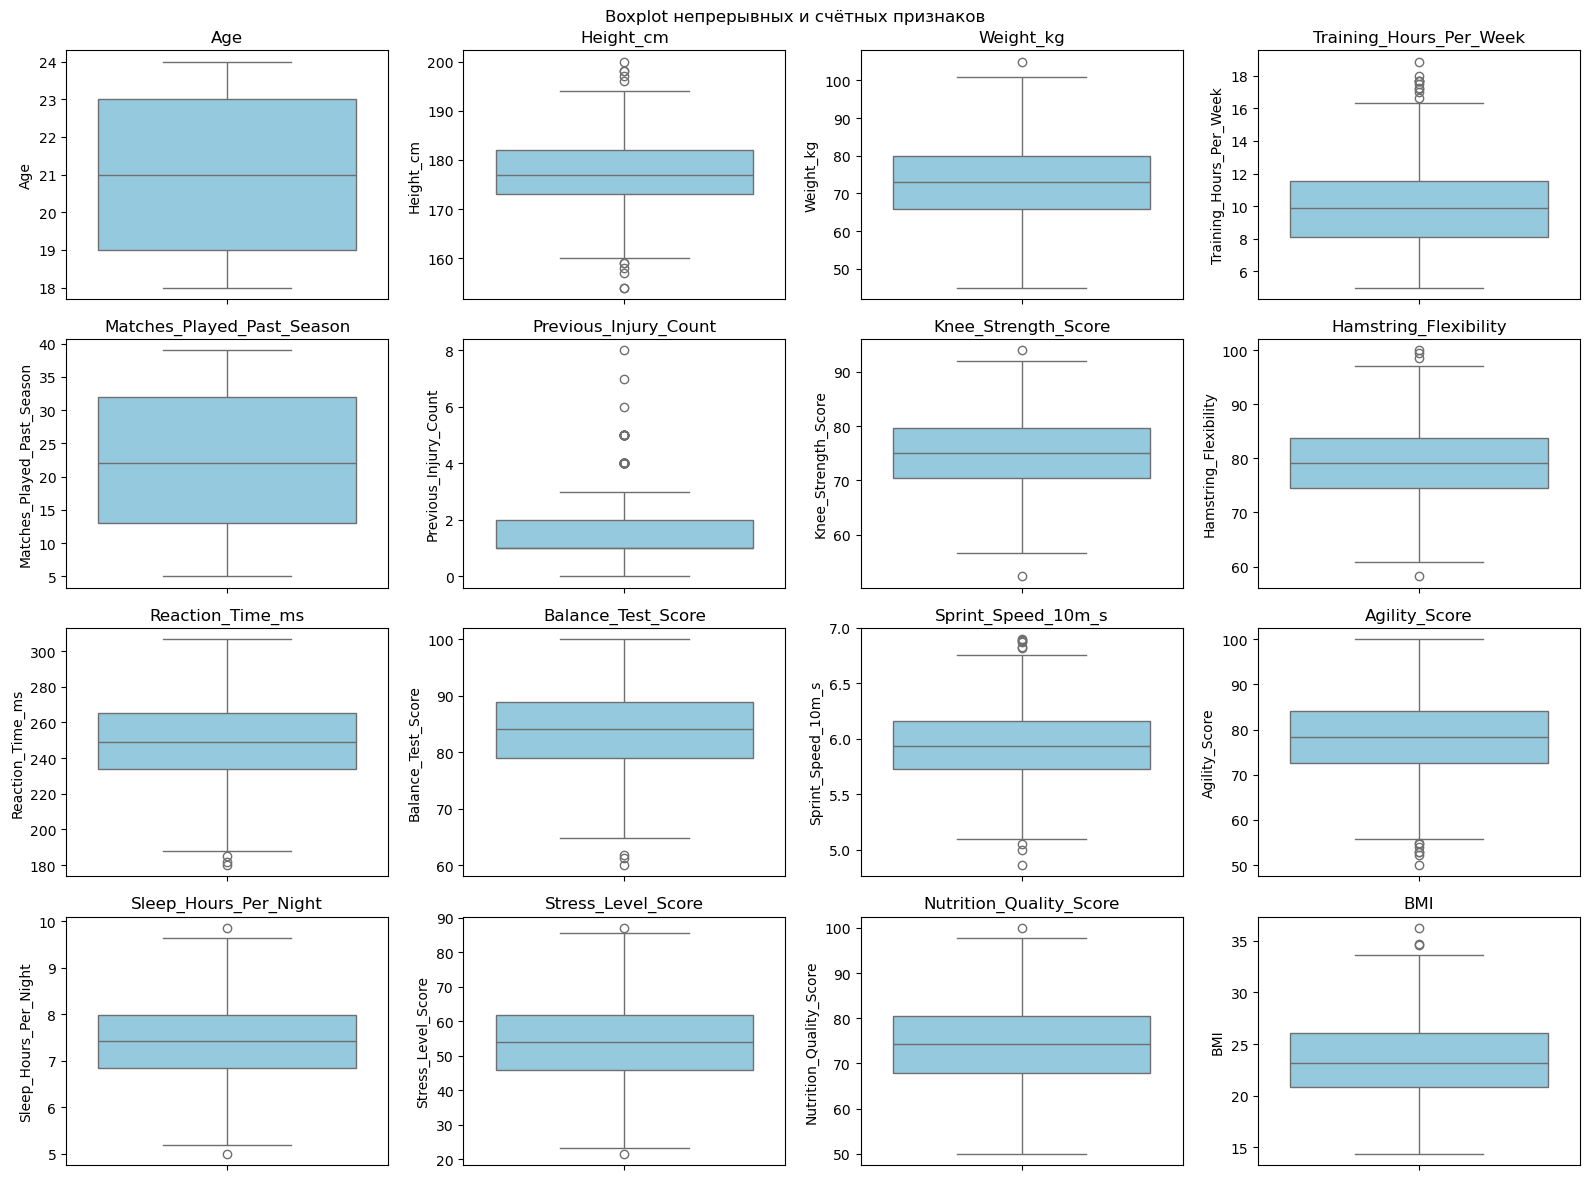

In [9]:
# Бинарные признаки (0/1) на выбросы не проверяем
binary_cols = [c for c in df.columns if df[c].nunique() == 2]
cont_cols = [c for c in df.columns if c not in binary_cols]

q1, q3 = df[cont_cols].quantile(0.25), df[cont_cols].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (df[cont_cols] < low) | (df[cont_cols] > high)

out_table = pd.DataFrame({
    'min': df[cont_cols].min(), 'max': df[cont_cols].max(),
    'нижняя граница': low, 'верхняя граница': high,
    'выбросов': is_out.sum(), 'доля, %': is_out.mean() * 100,
}).round(2)
display(out_table)
print(f"Строк хотя бы с одним выбросом: {int(is_out.any(axis=1).sum())} из {len(df)} "
      f"({is_out.any(axis=1).mean() * 100:.1f} %)")

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), cont_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.suptitle('Boxplot непрерывных и счётных признаков')
plt.tight_layout()
plt.show()

**Решение: выбросы не удаляем.** Основания по результатам таблицы и графиков:

- Хотя бы один IQR-выброс есть у 115 из 800 строк (14.4 %). Удаление таких строк сокращает и без того небольшую выборку (800 объектов) более чем на десятую часть.
- Основной источник — `Previous_Injury_Count` (63 выброса, 7.9 %). Это дискретный счётчик 0–8 травм; значения 4–8 редки, но реалистичны и сами по себе информативны для прогноза травмы, а не являются ошибками измерения.
- В остальных признаках выбросов единицы (0–11 точек на признак), значения лежат в правдоподобных диапазонах (возраст 18–24, рост 154–200 см, BMI 14–36). Ошибок вроде отрицательных или нулевых значений нет.
- Многие тестовые шкалы упираются в границы 50 и 100 (`Hamstring_Flexibility`, `Balance_Test_Score`, `Agility_Score`, `Nutrition_Quality_Score`): значения «срезаны» границей шкалы, а не искажены.

Чтобы проверить, что это не ухудшает модели, в конце ноутбука есть сравнение: те же модели обучаются на всех данных и на данных без выбросов.

## Формирование выборок и стандартизация

Данные делим на обучающую (80 %, 640 строк) и тестовую (20 %, 160 строк) части со стратификацией по целевой переменной. **Стандартизация** (`StandardScaler`) для логистической регрессии и SVM выполняется внутри `Pipeline`: среднее и стандартное отклонение считаются только по обучающей части (и по обучающим фолдам при кросс-валидации), поэтому утечки информации из теста нет. Для CART масштабирование не нужно: дерево сравнивает признаки с порогами и инвариантно к монотонным преобразованиям.

`BMI` вычисляется из `Weight_kg` и `Height_cm`, то есть почти линейно зависим от них; для логистической регрессии это мультиколлинеарность, которую $L_2$-регуляризация сглаживает. Для чистоты эксперимента признаки оставлены.

In [10]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print('Признаков:', X.shape[1])
print('train:', X_train.shape, ' доля класса 1:', round(y_train.mean(), 3))
print('test: ', X_test.shape, ' доля класса 1:', round(y_test.mean(), 3))

Признаков: 20
train: (640, 20)  доля класса 1: 0.5
test:  (160, 20)  доля класса 1: 0.5


## Модели и подбор гиперпараметров

Обучаем три модели бинарной классификации. Гиперпараметры подбираются перебором по сетке (`GridSearchCV`) на 5-кратной стратифицированной кросс-валидации по обучающей выборке; метрика отбора — ROC-AUC (классы сбалансированы, нужна оценка качества ранжирования, не зависящая от порога).

- **Логистическая регрессия** с $L_2$-штрафом: подбирается $C$ (обратная сила регуляризации).
- **SVM**: линейное и RBF-ядро, подбираются $C$ и `gamma`.
- **CART** (`DecisionTreeClassifier`): подбираются критерий, максимальная глубина и минимальный размер листа (ограничение сложности против переобучения).

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Логистическая регрессия': (
        Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=5000))]),
        {'clf__C': np.logspace(-3, 3, 13)}),
    'SVM': (
        Pipeline([('scaler', StandardScaler()), ('clf', SVC(probability=True, random_state=42))]),
        {'clf__kernel': ['linear', 'rbf'], 'clf__C': [0.01, 0.1, 1, 10, 100],
         'clf__gamma': ['scale', 0.001, 0.01, 0.1]}),
    'CART': (
        DecisionTreeClassifier(random_state=42),
        {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5, 10, 20],
         'criterion': ['gini', 'entropy']}),
}

fitted = {}
rows = []
for name, (estimator, grid) in models.items():
    gs = GridSearchCV(estimator, grid, cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
    fitted[name] = gs
    best = gs.best_index_
    rows.append({'модель': name, 'лучшие параметры': gs.best_params_,
                 'CV ROC-AUC': gs.cv_results_['mean_test_score'][best],
                 'std': gs.cv_results_['std_test_score'][best]})
pd.DataFrame(rows).style.format({'CV ROC-AUC': '{:.3f}', 'std': '{:.3f}'})

,модель,лучшие параметры,CV ROC-AUC,std
0,Логистическая регрессия,{'clf__C': np.float64(0.01)},0.991,0.005
1,SVM,"{'clf__C': 1, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}",0.991,0.006
2,CART,"{'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 10}",0.886,0.015


## Оценка качества на тестовой выборке

Тестовая выборка использовалась один раз, после выбора гиперпараметров. Метрики: accuracy (с 95 % доверительным интервалом Уилсона), precision, recall, F1, ROC-AUC; матрицы ошибок и ROC-кривые.

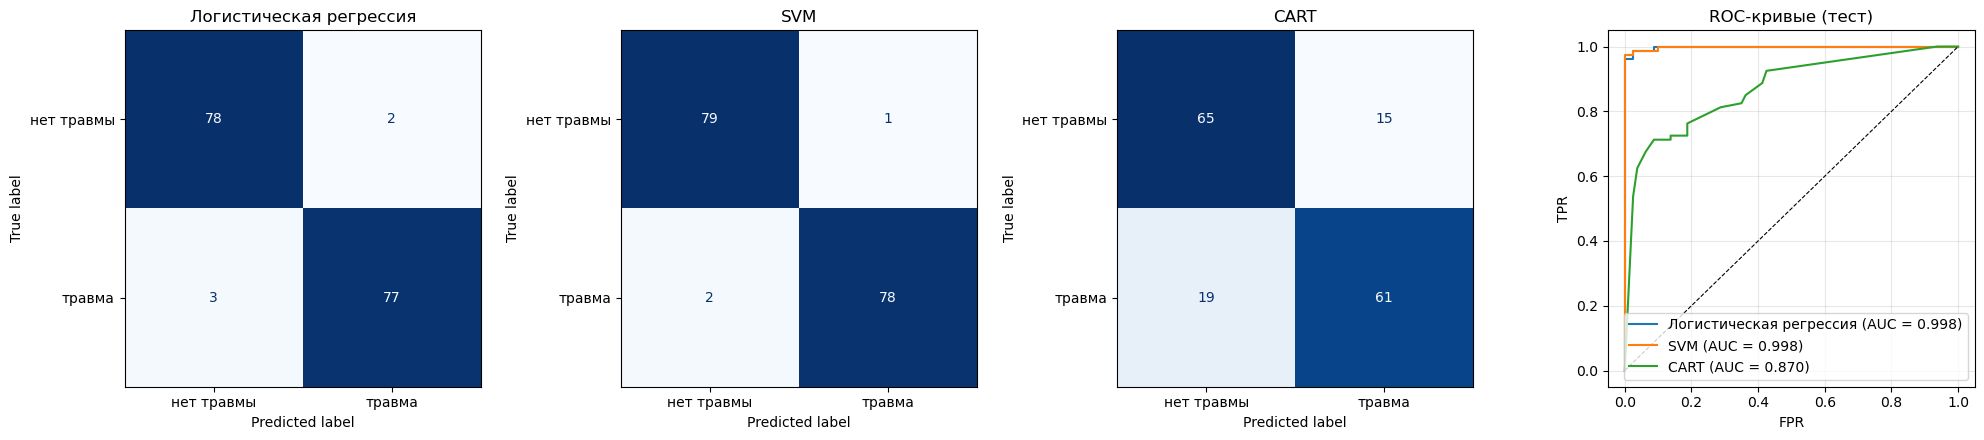

,accuracy,accuracy 95% ДИ,precision,recall,F1,ROC-AUC
модель,,,,,,
Логистическая регрессия,0.969,0.929–0.987,0.975,0.963,0.969,0.998
SVM,0.981,0.946–0.994,0.987,0.975,0.981,0.998
CART,0.787,0.718–0.844,0.803,0.762,0.782,0.870


In [12]:
def wilson(p, n, z=1.96):
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

rows = []
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, gs) in zip(axes[:3], fitted.items()):
    pred = gs.predict(X_test)
    proba = gs.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, pred)
    lo, hi = wilson(acc, len(y_test))
    rows.append({'модель': name, 'accuracy': acc, 'accuracy 95% ДИ': f'{lo:.3f}–{hi:.3f}',
                 'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)})
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['нет травмы', 'травма']).plot(
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[3].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[3].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[3].set_xlabel('FPR'); axes[3].set_ylabel('TPR'); axes[3].set_title('ROC-кривые (тест)')
axes[3].legend(loc='lower right'); axes[3].grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index('модель').style.format(
    {'accuracy': '{:.3f}', 'precision': '{:.3f}', 'recall': '{:.3f}', 'F1': '{:.3f}', 'ROC-AUC': '{:.3f}'})

**Выводы по качеству моделей**

- **Логистическая регрессия и SVM (RBF) работают почти одинаково и очень хорошо:** accuracy 0.969 и 0.981, F1 0.969 и 0.981, ROC-AUC 0.998 у обеих; кросс-валидационный ROC-AUC на обучающей части одинаков — 0.991. Ошибки на тесте: у логистической регрессии 2 ложных срабатывания и 3 пропущенные травмы из 160, у SVM — 1 и 2.
- **Разница между ними статистически неразличима.** Тест состоит из 160 объектов, один объект — это 0.6 п.п. accuracy, а доверительные интервалы пересекаются (0.929–0.987 против 0.946–0.994). Утверждать, что SVM лучше, нельзя; при равном качестве логистическая регрессия предпочтительнее как более простая и интерпретируемая модель.
- **CART заметно слабее:** accuracy 0.787, F1 0.782, ROC-AUC 0.870 (CV — 0.886). Он ошибается в 34 случаях из 160 (15 ложных срабатываний и 19 пропущенных травм). Вероятная причина — вклад в риск травмы дают сразу много признаков, действующих примерно аддитивно (линейно), а дерево строит ступенчатые разбиения по одному признаку и на 640 объектах не может аппроксимировать такую зависимость без глубокого переобучения.
- **Какую ошибку считать более важной.** Для задачи прогноза травм дороже пропуск травмы (ложноотрицательный ответ), поэтому важен recall: 0.963 у логистической регрессии, 0.975 у SVM и 0.762 у CART. Если нужен более высокий recall, у линейных моделей порог вероятности можно снизить ценой роста ложных срабатываний.
- **Очень высокое качество стоит интерпретировать осторожно.** ROC-AUC около 0.998 при чистых данных, точно сбалансированных классах и «срезанных» границах шкал указывает на то, что данные, скорее всего, синтетические (сгенерированные по формуле); на реальных данных о травмах такого качества ожидать не следует.

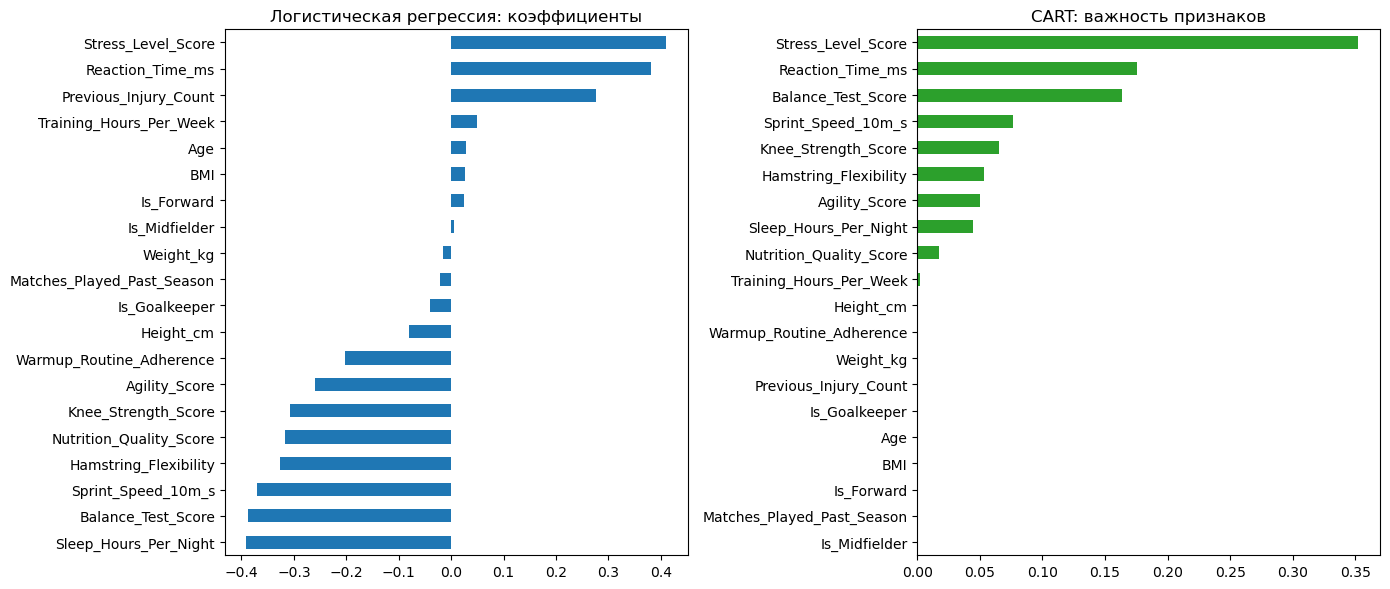

,коэф. лог. регрессии (станд. признаки),важность признака в CART
Stress_Level_Score,0.411,0.352
Sleep_Hours_Per_Night,-0.392,0.045
Balance_Test_Score,-0.387,0.164
Reaction_Time_ms,0.381,0.175
Sprint_Speed_10m_s,-0.370,0.077
Hamstring_Flexibility,-0.327,0.053
Nutrition_Quality_Score,-0.317,0.017
Knee_Strength_Score,-0.308,0.065
Previous_Injury_Count,0.277,0.000
Agility_Score,-0.259,0.050


In [13]:
lr = fitted['Логистическая регрессия'].best_estimator_.named_steps['clf']
tree = fitted['CART'].best_estimator_

imp = pd.DataFrame({
    'коэф. лог. регрессии (станд. признаки)': pd.Series(lr.coef_[0], index=X.columns),
    'важность признака в CART': pd.Series(tree.feature_importances_, index=X.columns),
})
imp = imp.reindex(imp.iloc[:, 0].abs().sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.iloc[:, 0].sort_values().plot.barh(ax=axes[0], color='tab:blue')
axes[0].set_title('Логистическая регрессия: коэффициенты')
imp.iloc[:, 1].sort_values().plot.barh(ax=axes[1], color='tab:green')
axes[1].set_title('CART: важность признаков')
plt.tight_layout()
plt.show()

imp.round(3)

**Что влияет на риск травмы.** В логистической регрессии признаки стандартизованы, поэтому коэффициенты сопоставимы по величине. Выше риск при большем уровне стресса (`Stress_Level_Score`, +0.41), большем времени реакции (+0.38) и большем числе прошлых травм (+0.28). Ниже риск при большем количестве сна (−0.39), лучшем балансе (−0.39), скорости спринта (−0.37), гибкости подколенных сухожилий (−0.33), качестве питания (−0.32), силе колена (−0.31), ловкости (−0.26) и при выполнении разминки (`Warmup_Routine_Adherence`, −0.20). Позиция, возраст, вес, рост, BMI, количество матчей и тренировочные часы практически не влияют (|коэф.| < 0.1).

CART опирается на те же ведущие признаки (стресс — 35 % важности, время реакции — 17.5 %, баланс — 16.4 %), но практически не использует `Previous_Injury_Count` и `Warmup_Routine_Adherence` (важность ≈ 0), хотя линейная модель выделяет их как значимые, — ещё один признак того, что дерево хуже улавливает эту структуру.

## Проверка чувствительности к выбросам

Обучаем те же модели с теми же гиперпараметрами на обучающей части без строк-выбросов (границы IQR считаются только по train) и оцениваем на нетронутой тестовой выборке.

In [14]:
# Чувствительность к выбросам: обучаем те же модели (с теми же гиперпараметрами) на train
# без строк-выбросов, границы IQR считаем только по train. Тест не чистим.
tr_cont = X_train[cont_cols]
q1t, q3t = tr_cont.quantile(0.25), tr_cont.quantile(0.75)
iqrt = q3t - q1t
mask = ~(((tr_cont < q1t - 1.5 * iqrt) | (tr_cont > q3t + 1.5 * iqrt)).any(axis=1))
print(f'Строк train: {len(X_train)} -> без выбросов: {int(mask.sum())}')

rows = []
for name, gs in fitted.items():
    m_all = gs.best_estimator_
    m_clean = clone(m_all).fit(X_train[mask], y_train[mask])
    for tag, m in [('все данные', m_all), ('без выбросов', m_clean)]:
        pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
        rows.append({'модель': name, 'обучение на': tag, 'accuracy': accuracy_score(y_test, pred),
                     'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, proba)})
pd.DataFrame(rows).style.format({'accuracy': '{:.3f}', 'F1': '{:.3f}', 'ROC-AUC': '{:.3f}'})

Строк train: 640 -> без выбросов: 594


,модель,обучение на,accuracy,F1,ROC-AUC
0,Логистическая регрессия,все данные,0.969,0.969,0.998
1,Логистическая регрессия,без выбросов,0.975,0.975,0.998
2,SVM,все данные,0.981,0.981,0.998
3,SVM,без выбросов,0.975,0.975,0.998
4,CART,все данные,0.787,0.782,0.870
5,CART,без выбросов,0.769,0.770,0.812


**Вывод по выбросам.** Удаление выбросов (46 из 640 обучающих строк, 7.2 %) не улучшило модели: у логистической регрессии accuracy 0.969 → 0.975, у SVM 0.981 → 0.975 — изменения в пределах одного тестового объекта (0.6 п.п.), то есть шум. У CART качество ухудшилось (ROC-AUC 0.870 → 0.812). Это подтверждает решение не удалять выбросы: они не мешают линейным моделям и SVM, а для дерева удаление редких, но информативных значений скорее вредно.

## Итог

1. Данные чистые: без пропусков и дубликатов, классы сбалансированы; выбросы сохранены по причинам, описанным выше.
2. Лучшие модели — **логистическая регрессия** и **SVM с RBF-ядром** (accuracy ≈ 0.97–0.98, ROC-AUC 0.998), различие между ними в пределах статистического шума; **CART** уступает (accuracy 0.79).
3. Основные факторы риска травмы — высокий уровень стресса, большое время реакции и число прошлых травм; защитные — сон, баланс, скорость, гибкость, питание, сила колена и регулярная разминка.